 # Stock Market Analysis and Prediction (ARIMA)
 
 Tickers: NVDA, AAPL, JPM, XOM, JNJ

 Question: Can ARIMA beat a naive "tomorrow = today" baseline?



In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import pmdarima as pm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error

TICKERS = ["NVDA", "AAPL", "JPM", "XOM", "JNJ"]
START, END = "2019-01-01", "2026-10-01"
TEST_FRAC = 0.20
plt.rcParams["figure.figsize"] = (11, 4)

In [5]:
raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
raw.to_csv("raw_ohlcv.csv")
print(raw.shape)

(1947, 25)


In [6]:
close = raw["Close"][TICKERS].copy()
close.index = pd.DatetimeIndex(close.index)
print("Missing values before:\n", close.isna().sum())
close = close.asfreq("B").ffill().dropna()
volume = raw["Volume"][TICKERS].reindex(close.index).ffill()
log_price = np.log(close)
log_ret = log_price.diff().dropna()
close.to_csv("clean_adj_close.csv")

Missing values before:
 Ticker
NVDA    0
AAPL    0
JPM     0
XOM     0
JNJ     0
dtype: int64


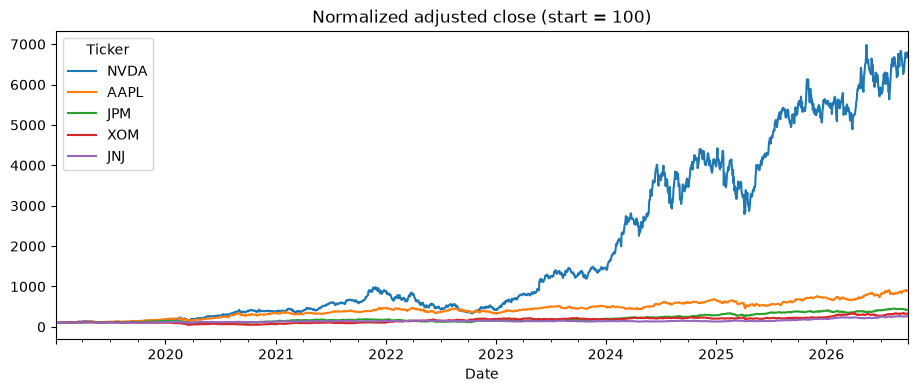

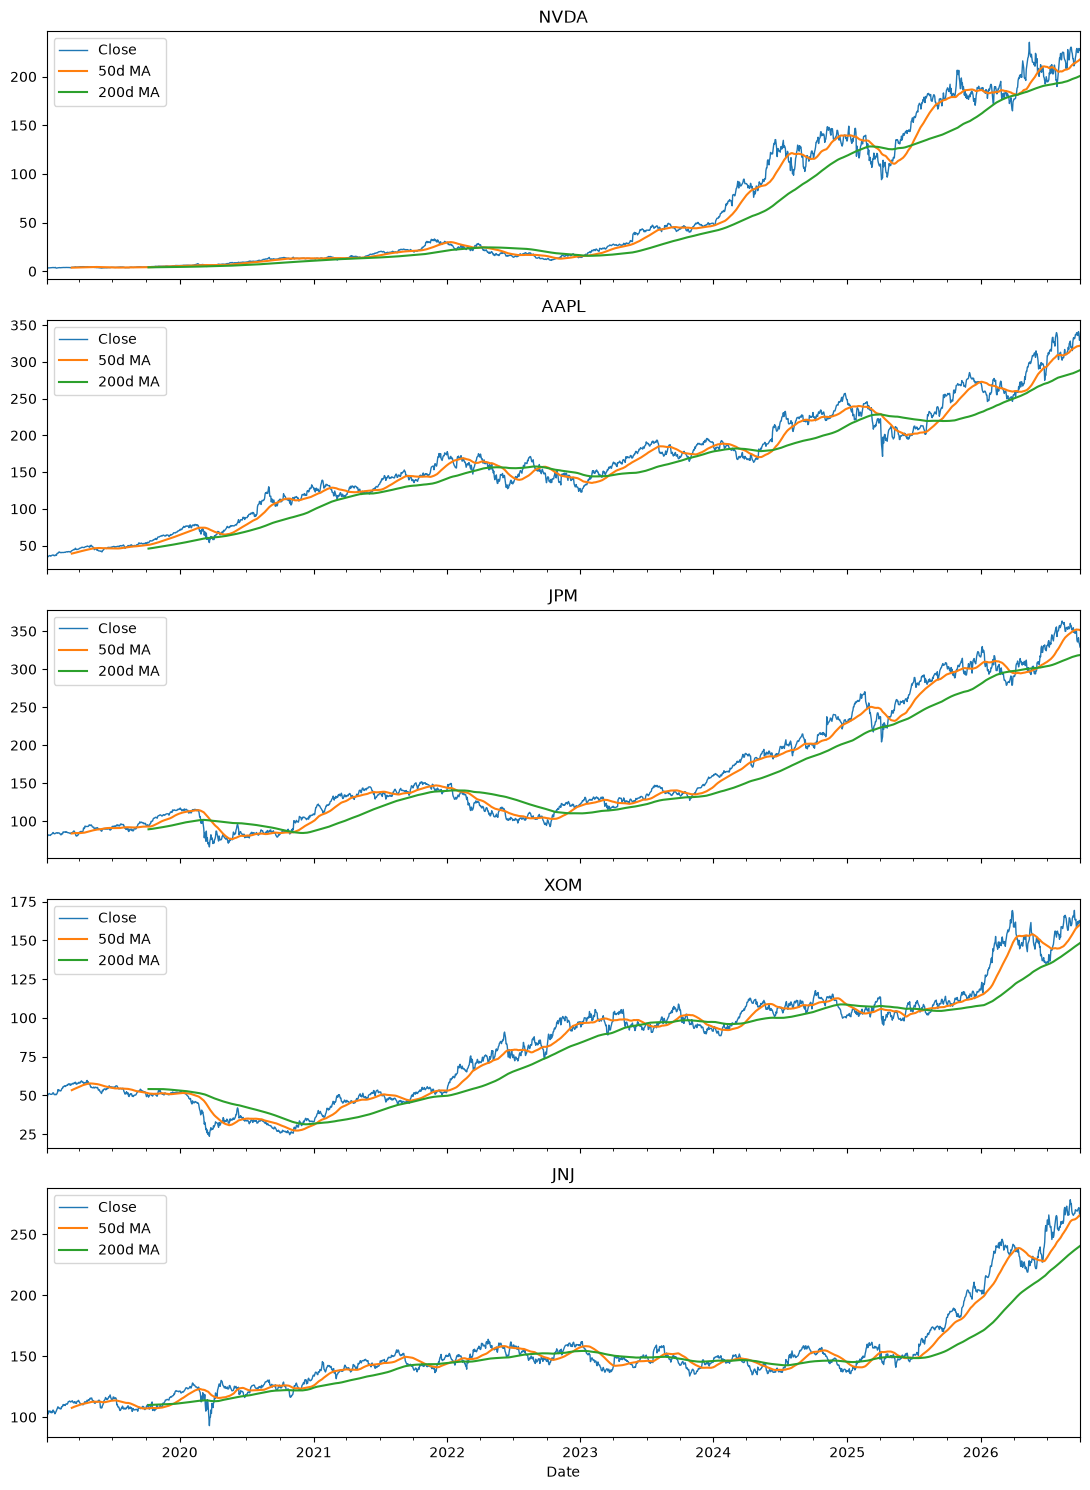

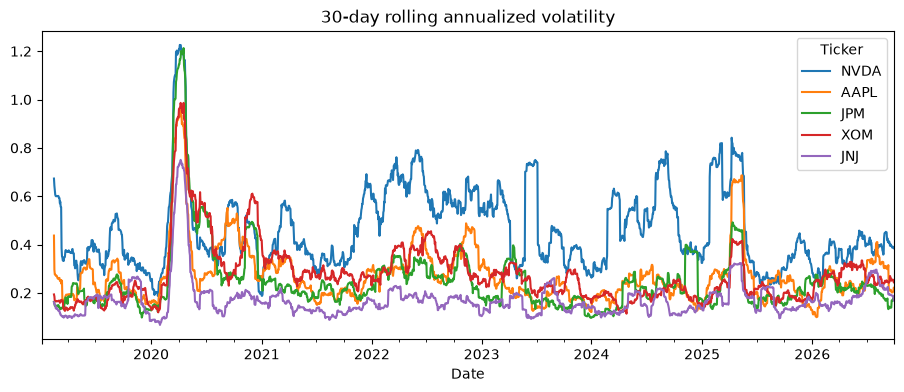

Ticker  NVDA  AAPL   JPM   XOM   JNJ
Ticker                              
NVDA    1.00  0.55  0.34  0.17  0.07
AAPL    0.55  1.00  0.41  0.27  0.30
JPM     0.34  0.41  1.00  0.51  0.33
XOM     0.17  0.27  0.51  1.00  0.27
JNJ     0.07  0.30  0.33  0.27  1.00


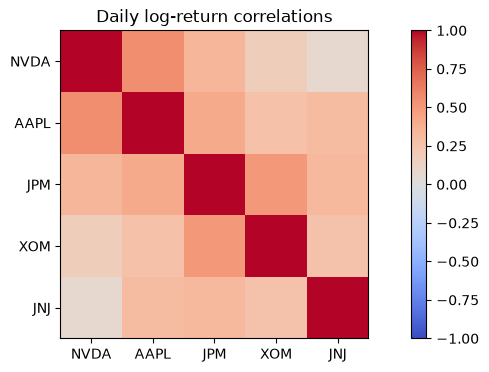

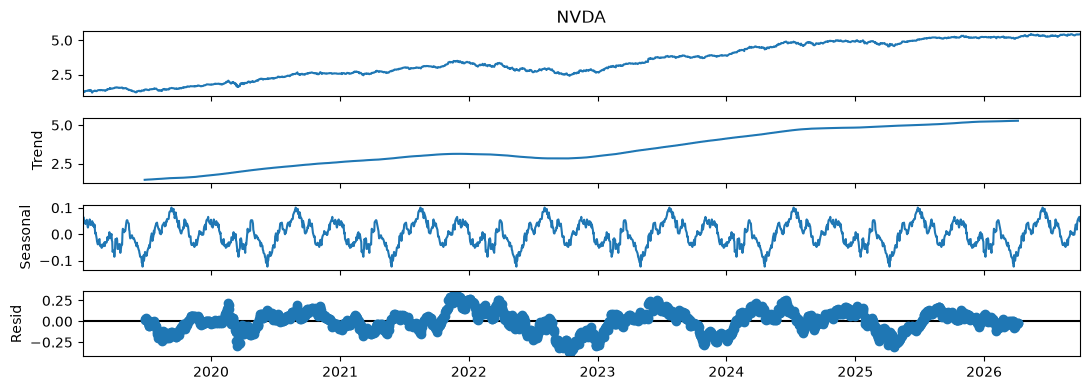

        ann_return  ann_vol  sharpe_like
Ticker                                  
NVDA         0.526    0.493        1.067
AAPL         0.273    0.301        0.906
JPM          0.176    0.287        0.615
XOM          0.149    0.303        0.491
JNJ          0.117    0.189        0.620


In [17]:
# Normalized price (start = 100) for comparison
(close / close.iloc[0] * 100).plot(title="Normalized adjusted close (start = 100)")
plt.savefig("images/normalized_prices.png", dpi=150, bbox_inches="tight")
plt.show()
# Moving averages + rolling volatility per ticker
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(11, 3 * len(TICKERS)), sharex=True)
for ax, t in zip(axes, TICKERS):
    close[t].plot(ax=ax, label="Close", lw=1)
    close[t].rolling(50).mean().plot(ax=ax, label="50d MA")
    close[t].rolling(200).mean().plot(ax=ax, label="200d MA")
    ax.set_title(t); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

(log_ret.rolling(30).std() * np.sqrt(252)).plot(title="30-day rolling annualized volatility")
plt.show()

# Return correlations
corr = log_ret.corr()
print(corr.round(2))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(TICKERS)), TICKERS); plt.yticks(range(len(TICKERS)), TICKERS)
plt.colorbar(); plt.title("Daily log-return correlations"); plt.show()

# Trend/seasonality decomposition (example: NVDA, ~yearly cycle of 252 trading days)
seasonal_decompose(log_price["NVDA"], model="additive", period=252).plot()
plt.show()

# Summary stats
summary = pd.DataFrame({
    "ann_return": log_ret.mean() * 252,
    "ann_vol": log_ret.std() * np.sqrt(252),
})
summary["sharpe_like"] = summary["ann_return"] / summary["ann_vol"]
print(summary.round(3))

In [8]:
def adf_report(series, name):
    stat, p, *_ = adfuller(series.dropna(), autolag="AIC")
    verdict = "stationary" if p < 0.05 else "NON-stationary"
    return {"series": name, "ADF stat": round(stat, 3), "p-value": round(p, 4), "verdict": verdict}

rows = []
for t in TICKERS:
    rows.append(adf_report(log_price[t], f"{t} log price"))
    rows.append(adf_report(log_ret[t], f"{t} log return"))
print(pd.DataFrame(rows).to_string(index=False))
# log prices non-stationary, log returns stationary -> d = 1

         series  ADF stat  p-value        verdict
 NVDA log price    -0.701   0.8464 NON-stationary
NVDA log return   -14.427   0.0000     stationary
 AAPL log price    -2.205   0.2045 NON-stationary
AAPL log return   -14.856   0.0000     stationary
  JPM log price    -0.375   0.9143 NON-stationary
 JPM log return   -12.777   0.0000     stationary
  XOM log price    -0.296   0.9260 NON-stationary
 XOM log return   -16.081   0.0000     stationary
  JNJ log price    -0.004   0.9582 NON-stationary
 JNJ log return   -12.354   0.0000     stationary


In [9]:
n_test = int(len(log_price) * TEST_FRAC)
train = log_price.iloc[:-n_test]
test = log_price.iloc[-n_test:]
print("Train:", train.index[0].date(), "->", train.index[-1].date())
print("Test: ", test.index[0].date(), "->", test.index[-1].date())

Train: 2019-01-02 -> 2025-03-13
Test:  2025-03-14 -> 2026-09-30


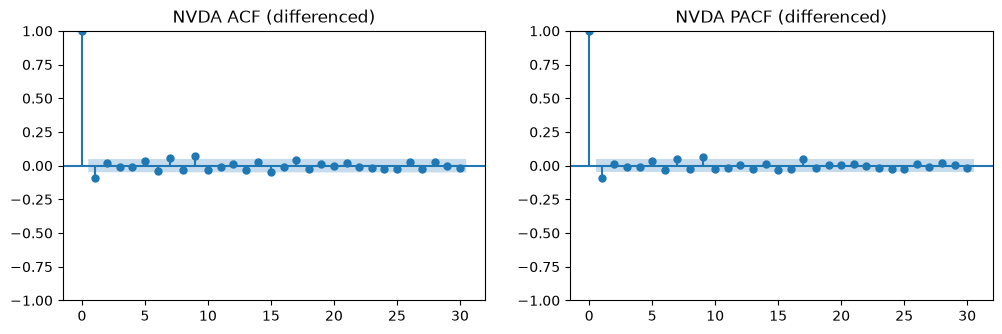

NVDA: ARIMA(1, 1, 0)  AIC=-6506.4  BIC=-6490.3
AAPL: ARIMA(1, 1, 0)  AIC=-8224.8  BIC=-8208.6
JPM: ARIMA(3, 1, 2)  AIC=-8318.6  BIC=-8280.9
XOM: ARIMA(0, 1, 0)  AIC=-8089.5  BIC=-8084.1
JNJ: ARIMA(1, 1, 4)  AIC=-9779.0  BIC=-9746.6


In [10]:
t = "NVDA"  # ACF/PACF shown for NVDA as a representative example.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(train[t].diff().dropna(), lags=30, ax=ax[0], title=f"{t} ACF (differenced)")
plot_pacf(train[t].diff().dropna(), lags=30, ax=ax[1], title=f"{t} PACF (differenced)")
plt.show()

orders = {}
for tk in TICKERS:
    m = pm.auto_arima(
        train[tk], d=1, seasonal=False, information_criterion="aic",
        max_p=5, max_q=5, stepwise=True, suppress_warnings=True,
    )
    orders[tk] = m.order
    print(f"{tk}: ARIMA{m.order}  AIC={m.aic():.1f}  BIC={m.bic():.1f}")

In [11]:
def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100

results, fits = [], {}
for tk in TICKERS:
    order = orders[tk]
    res = ARIMA(train[tk], order=order).fit()

    # (a) Multi-step forecast over the whole test window, with 95% CI
    fc = res.get_forecast(steps=n_test)
    fc_mean = np.exp(fc.predicted_mean)
    ci = np.exp(fc.conf_int(alpha=0.05))

    # (b) Walk-forward, one-step-ahead (fixed params, new data appended each step)
    appended = res.append(test[tk], refit=False)
    one_step = np.exp(appended.predict(start=len(train), end=len(train) + n_test - 1))

    actual = np.exp(test[tk])
    naive = np.exp(log_price[tk].shift(1).loc[test.index])  # tomorrow = today

    for label, pred in [("ARIMA walk-forward", one_step),
                        ("ARIMA multi-step", fc_mean),
                        ("Naive (t-1)", naive)]:
        pred = pd.Series(np.asarray(pred), index=test.index)
        results.append({
            "ticker": tk, "model": label, "order": order,
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "MAE": mean_absolute_error(actual, pred),
            "MAPE %": mape(actual, pred),
        })

    # Ljung-Box on residuals (want p > 0.05 = no leftover autocorrelation)
    lb = acorr_ljungbox(res.resid.iloc[1:], lags=[10], return_df=True)
    print(f"{tk} Ljung-Box p-value (lag 10): {lb['lb_pvalue'].iloc[0]:.4f}")

    fits[tk] = dict(actual=actual, one_step=one_step, fc_mean=fc_mean, ci=ci)

NVDA Ljung-Box p-value (lag 10): 0.0578
AAPL Ljung-Box p-value (lag 10): 0.0000
JPM Ljung-Box p-value (lag 10): 0.0000


C:\Users\yadav\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


XOM Ljung-Box p-value (lag 10): 0.0000
JNJ Ljung-Box p-value (lag 10): 0.0080


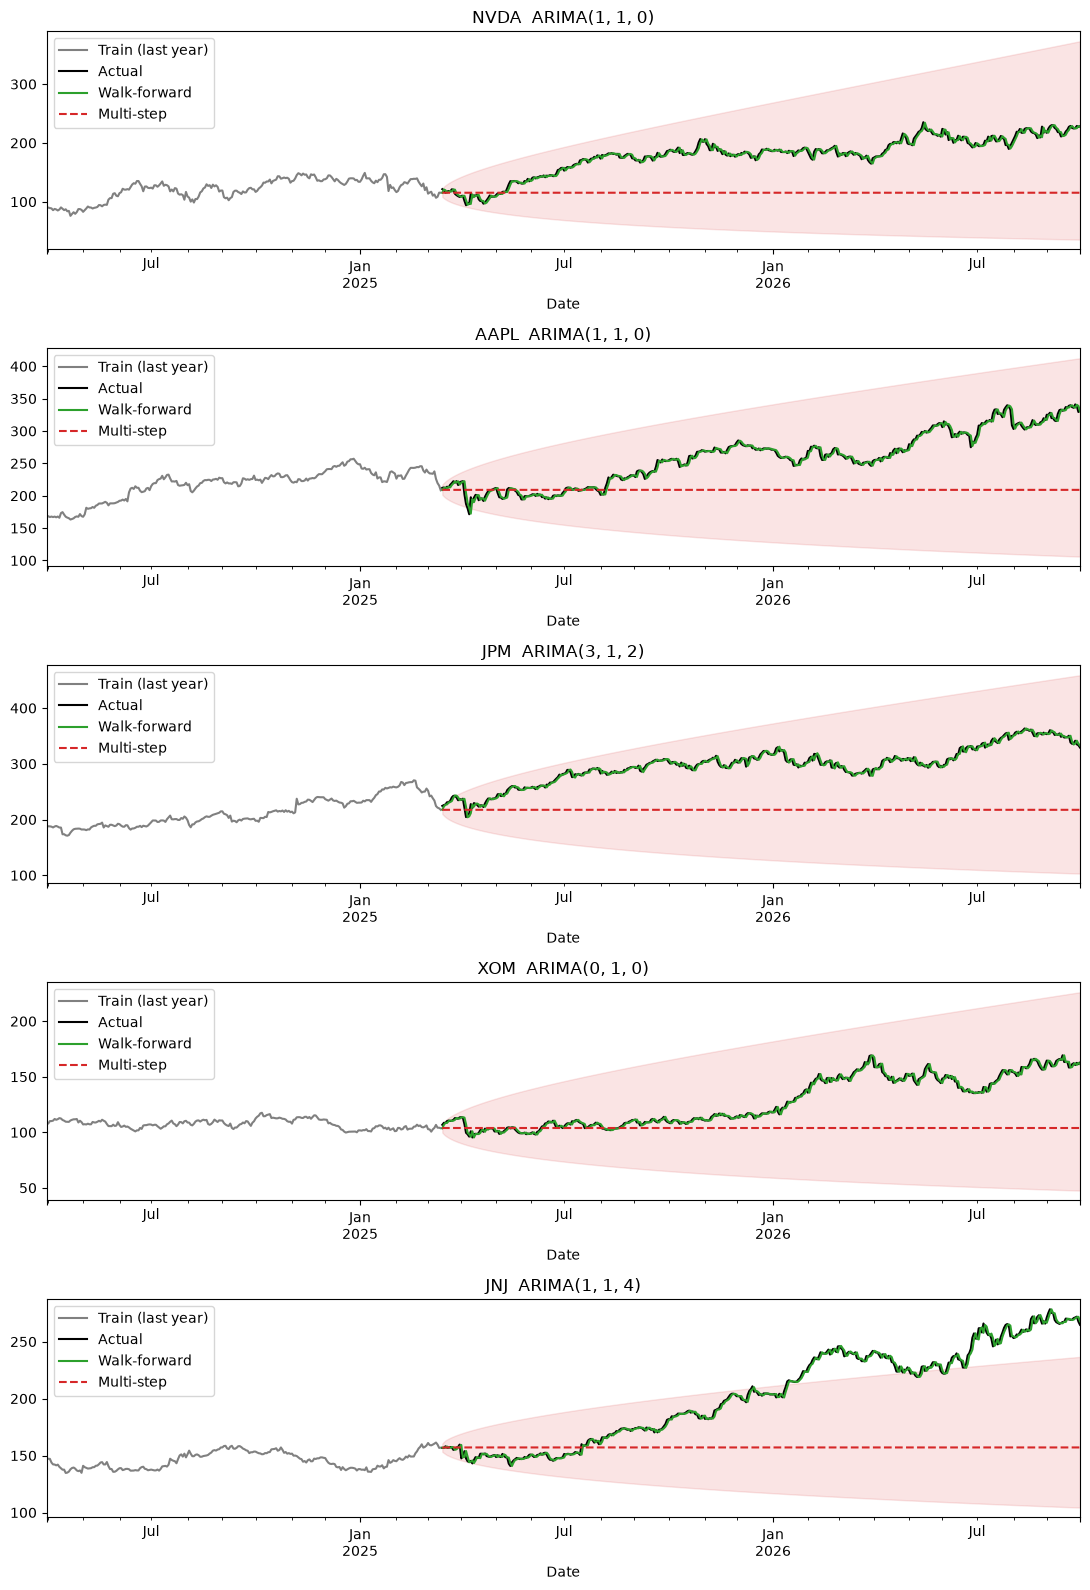

In [19]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(11, 3.2 * len(TICKERS)))
for ax, tk in zip(axes, TICKERS):
    f = fits[tk]
    np.exp(train[tk]).iloc[-250:].plot(ax=ax, label="Train (last year)", color="gray")
    f["actual"].plot(ax=ax, label="Actual", color="black")
    pd.Series(np.asarray(f["one_step"]), index=test.index).plot(ax=ax, label="Walk-forward", color="tab:green")
    pd.Series(np.asarray(f["fc_mean"]), index=test.index).plot(ax=ax, label="Multi-step", color="tab:red", ls="--")
    ax.fill_between(test.index, f["ci"].iloc[:, 0], f["ci"].iloc[:, 1], color="tab:red", alpha=0.12)
    ax.set_title(f"{tk}  ARIMA{orders[tk]}"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("images/forecast_vs_actual.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
res_df = pd.DataFrame(results).round(3)
print(res_df.to_string(index=False))
res_df.to_csv("model_results.csv", index=False)

# Does walk-forward ARIMA beat naive? (lower RMSE = better)
piv = res_df.pivot(index="ticker", columns="model", values="RMSE")
piv["ARIMA beats naive?"] = piv["ARIMA walk-forward"] < piv["Naive (t-1)"]
print(piv)

ticker              model     order   RMSE    MAE  MAPE %
  NVDA ARIMA walk-forward (1, 1, 0)  4.241  3.175   1.807
  NVDA   ARIMA multi-step (1, 1, 0) 71.586 65.276  34.258
  NVDA        Naive (t-1) (1, 1, 0)  4.252  3.165   1.803
  AAPL ARIMA walk-forward (1, 1, 0)  4.562  3.051   1.205
  AAPL   ARIMA multi-step (1, 1, 0) 64.528 52.759  18.651
  AAPL        Naive (t-1) (1, 1, 0)  4.515  3.008   1.187
   JPM ARIMA walk-forward (3, 1, 2)  4.283  3.166   1.082
   JPM   ARIMA multi-step (3, 1, 2) 86.806 80.368  26.043
   JPM        Naive (t-1) (3, 1, 2)  4.203  3.059   1.046
   XOM ARIMA walk-forward (0, 1, 0)  2.134  1.547   1.194
   XOM   ARIMA multi-step (0, 1, 0) 32.859 24.882  17.187
   XOM        Naive (t-1) (0, 1, 0)  2.134  1.547   1.194
   JNJ ARIMA walk-forward (1, 1, 4)  2.626  1.849   0.895
   JNJ   ARIMA multi-step (1, 1, 4) 62.241 50.029  21.812
   JNJ        Naive (t-1) (1, 1, 4)  2.546  1.795   0.871
model   ARIMA multi-step  ARIMA walk-forward  Naive (t-1)  ARIMA beats n

In [14]:
from scipy import stats

def diebold_mariano(actual, pred_model, pred_baseline, h=1):
    """DM test on squared-error loss with the Harvey-Leybourne-Newbold small-sample correction.
    H0: equal predictive accuracy. Negative DM stat => model has LOWER error than baseline."""
    e1 = np.asarray(actual - pred_model, dtype=float)
    e2 = np.asarray(actual - pred_baseline, dtype=float)
    d = e1 ** 2 - e2 ** 2                      # loss differential
    n = len(d)
    d_mean = d.mean()
    # long-run variance of d (autocovariances up to lag h-1; for h=1 this is just the variance)
    gamma0 = np.var(d, ddof=0)
    lrv = gamma0 + 2 * sum(
        np.cov(d[k:], d[:-k], ddof=0)[0, 1] for k in range(1, h)
    )
    if lrv <= 0 or np.isclose(lrv, 0):
        return np.nan, np.nan                  # identical forecasts (e.g., XOM ARIMA(0,1,0) == naive)
    dm = d_mean / np.sqrt(lrv / n)
    hln = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)   # HLN correction
    dm_adj = dm * hln
    p = 2 * (1 - stats.t.cdf(abs(dm_adj), df=n - 1))
    return dm_adj, p

dm_rows = []
for tk in TICKERS:
    actual = fits[tk]["actual"]
    arima_pred = pd.Series(np.asarray(fits[tk]["one_step"]), index=test.index)
    naive_pred = np.exp(log_price[tk].shift(1).loc[test.index])
    stat, p = diebold_mariano(actual, arima_pred, naive_pred, h=1)
    if np.isnan(p):
        verdict = "identical forecasts"
    elif p >= 0.05:
        verdict = "no significant difference"
    else:
        verdict = "ARIMA significantly better" if stat < 0 else "Naive significantly better"
    dm_rows.append({"ticker": tk, "DM stat": stat, "p-value": p, "verdict": verdict})

dm_df = pd.DataFrame(dm_rows).round(4)
print(dm_df.to_string(index=False))
dm_df.to_csv("dm_test_results.csv", index=False)
#p >= 0.05: cannot reject equal predictive accuracy.

ticker  DM stat  p-value                    verdict
  NVDA  -0.5016   0.6162  no significant difference
  AAPL   1.4323   0.1528  no significant difference
   JPM   1.9799   0.0484 Naive significantly better
   XOM      NaN      NaN        identical forecasts
   JNJ   3.7059   0.0002 Naive significantly better


In [15]:
# Naive "tomorrow = today" predicts no change, so it has no direction.
# Benchmarks used instead: (1) a 50% coin flip, and (2) an "always predict up" strategy
# (the share of up days in the test window).
dir_rows = []
for tk in TICKERS:
    actual = fits[tk]["actual"]
    prev = np.exp(log_price[tk].shift(1).loc[test.index])          # yesterday's actual close
    arima_pred = pd.Series(np.asarray(fits[tk]["one_step"]), index=test.index)

    actual_dir = np.sign(actual - prev)
    diff = arima_pred - prev
    pred_dir = np.sign(diff).where(diff.abs() > 1e-6 * prev, 0)
    mask = (actual_dir != 0) & (pred_dir != 0)                      # drop flat days / no-direction calls
    n = int(mask.sum())
    always_up = (actual_dir[actual_dir != 0] > 0).mean()
    if n == 0:
        # e.g., ARIMA(0,1,0) predicts "no change" every day, so it makes no directional call at all
        acc, p_vs_coin = np.nan, np.nan
    else:
        hits = int((actual_dir[mask] == pred_dir[mask]).sum())
        acc = hits / n
        # one-sided binomial test: is accuracy > 50%?
        p_vs_coin = stats.binomtest(hits, n, 0.5, alternative="greater").pvalue

    dir_rows.append({
        "ticker": tk, "n days": n,
        "ARIMA dir. accuracy %": acc * 100 if n else np.nan,
        "Always-up baseline %": always_up * 100,
        "p-value (acc > 50%)": p_vs_coin,
    })

dir_df = pd.DataFrame(dir_rows).round(3)
print(dir_df.to_string(index=False))
dir_df.to_csv("directional_accuracy.csv", index=False)
# Accuracy near 50% indicates no directional skill versus a coin flip.
# In a trending test window, an "always up" strategy can score above 50% with no skill.

ticker  n days  ARIMA dir. accuracy %  Always-up baseline %  p-value (acc > 50%)
  NVDA     374                 51.604                52.699                0.285
  AAPL     374                 49.733                53.985                0.562
   JPM     388                 51.289                56.443                0.324
   XOM       0                    NaN                55.928                  NaN
   JNJ     389                 48.586                54.756                0.729


In [16]:
summary_tbl = dm_df.merge(dir_df, on="ticker")
print(summary_tbl.to_string(index=False))
summary_tbl.to_csv("evaluation_summary.csv", index=False)

ticker  DM stat  p-value                    verdict  n days  ARIMA dir. accuracy %  Always-up baseline %  p-value (acc > 50%)
  NVDA  -0.5016   0.6162  no significant difference     374                 51.604                52.699                0.285
  AAPL   1.4323   0.1528  no significant difference     374                 49.733                53.985                0.562
   JPM   1.9799   0.0484 Naive significantly better     388                 51.289                56.443                0.324
   XOM      NaN      NaN        identical forecasts       0                    NaN                55.928                  NaN
   JNJ   3.7059   0.0002 Naive significantly better     389                 48.586                54.756                0.729


In [20]:
import os
print(os.getcwd())
print(os.listdir("images"))

c:\Users\yadav\Downloads\stock-arima-analysis
['forecast_vs_actual.png', 'normalized_prices.png']
